# Final DEC Training

This notebook trains the final Deep Embedded Clustering (DEC) model after completing hyperparameter selection.

The final model is trained using:

- the full dataset, without a train/validation split;
- the pretrained autoencoder encoder, kept frozen during DEC optimization;
- a fresh KMeans initialization fitted on the full-dataset embeddings;
- 5 clusters;
- the selected `alpha`;
- the selected learning rate;
- the selected target-distribution update interval;
- random seed 42 for the final training pipeline.

The resulting full-dataset cluster assignments are used for subsequent clustering evaluation, UMAP visualization, and cluster-profile analysis.

No hyperparameter selection is performed in this notebook. All hyperparameters are fixed based on the completed tuning experiments.

In [18]:
import random

import numpy as np
import pandas as pd
import torch

from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

In [19]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [20]:
# Final DEC configuration
N_CLUSTERS = 5

ALPHA = 0.5
LEARNING_RATE = 3e-3
UPDATE_INTERVAL = 20

BATCH_SIZE = 256
MAX_EPOCHS = 50

N_INIT = 20

config = {
    "dec": {
        "num_clusters": N_CLUSTERS,
        "alpha": ALPHA,
        "learning_rate": LEARNING_RATE,
        "update_interval": UPDATE_INTERVAL,
        "max_epochs": MAX_EPOCHS,
        "batch_size": BATCH_SIZE,
    }
}

SEED = 42

## Load the full dataset

Hyperparameter selection has already been completed. Therefore, the final DEC model is trained once using the **full processed dataset**, with no train/validation split.

The input is the same scaled feature representation used throughout the canonical DEC experiments. No preprocessing or hyperparameter selection is performed in this section.


In [21]:
X_scaled = pd.read_csv("../dataset/X_scaled.csv").values

print("X_scaled shape:", X_scaled.shape)

X_scaled shape: (99997, 7)


In [22]:
# Basic data sanity checks
print("Shape:", X_scaled.shape)
print("Dtype:", X_scaled.dtype)
print("Number of samples:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

print("NaN values:", np.isnan(X_scaled).sum())
print("Infinite values:", np.isinf(X_scaled).sum())

EXPECTED_FEATURES = 7
assert X_scaled.shape[1] == EXPECTED_FEATURES
assert np.isfinite(X_scaled).all()

print("Data checks passed.")

Shape: (99997, 7)
Dtype: float64
Number of samples: 99997
Number of features: 7
NaN values: 0
Infinite values: 0
Data checks passed.


## Pretrained Encoder

The final DEC model uses the pretrained autoencoder encoder from the canonical pipeline. The encoder is kept **frozen** during DEC training, so its learned representation is not updated during clustering.

The same pretrained encoder and checkpoint used in the canonical experiments are retained for final training.


In [23]:
from src.dec.train_dec import train_dec_final

results = train_dec_final(
    X=X_scaled,
    ae_checkpoint_path=PROJECT_ROOT / "models" / "autoencoder_weights.pth",
    config=config,
    seed=SEED,
)

Epoch 1/50, Train KL Loss = 0.0352
Epoch 2/50, Train KL Loss = 0.0342
Epoch 3/50, Train KL Loss = 0.0341
Epoch 4/50, Train KL Loss = 0.0340
Epoch 5/50, Train KL Loss = 0.0342
Epoch 6/50, Train KL Loss = 0.0341
Epoch 7/50, Train KL Loss = 0.0342
Epoch 8/50, Train KL Loss = 0.0341
Epoch 9/50, Train KL Loss = 0.0342
Epoch 10/50, Train KL Loss = 0.0341
Epoch 11/50, Train KL Loss = 0.0341
Epoch 12/50, Train KL Loss = 0.0341
Epoch 13/50, Train KL Loss = 0.0341
Epoch 14/50, Train KL Loss = 0.0342
Epoch 15/50, Train KL Loss = 0.0342
Epoch 16/50, Train KL Loss = 0.0341
Epoch 17/50, Train KL Loss = 0.0341
Epoch 18/50, Train KL Loss = 0.0341
Epoch 19/50, Train KL Loss = 0.0342
Epoch 20/50, Train KL Loss = 0.0342
Epoch 21/50, Train KL Loss = 0.0626
Epoch 22/50, Train KL Loss = 0.0625
Epoch 23/50, Train KL Loss = 0.0623
Epoch 24/50, Train KL Loss = 0.0625
Epoch 25/50, Train KL Loss = 0.0623
Epoch 26/50, Train KL Loss = 0.0624
Epoch 27/50, Train KL Loss = 0.0622
Epoch 28/50, Train KL Loss = 0.0624
E

In [24]:
from pathlib import Path
import numpy as np

# Create output directory
final_dir = Path(PROJECT_ROOT / "final_dec" / "model")
final_dir.mkdir(parents=True, exist_ok=True)

# Save final DEC outputs
np.save(final_dir / "final_embeddings.npy", results["Z_full"])
np.save(final_dir / "final_labels.npy", results["full_labels"])
np.save(final_dir / "final_q.npy", results["q_full"])
np.save(final_dir / "final_p.npy", results["p_full"])
np.save(final_dir / "cluster_centers.npy", results["cluster_centers"])

# Verify outputs
print("Embeddings shape:", results["Z_full"].shape)
print("Labels shape:", results["full_labels"].shape)
print("Q shape:", results["q_full"].shape)
print("P shape:", results["p_full"].shape)
print("Cluster centers shape:", results["cluster_centers"].shape)

print("Embeddings finite:", np.isfinite(results["Z_full"]).all())
print("Q finite:", np.isfinite(results["q_full"]).all())
print("P finite:", np.isfinite(results["p_full"]).all())
print("All outputs saved successfully.")

Embeddings shape: (99997, 5)
Labels shape: (99997,)
Q shape: (99997, 5)
P shape: (99997, 5)
Cluster centers shape: (5, 5)
Embeddings finite: True
Q finite: True
P finite: True
All outputs saved successfully.


In [25]:
import json
from pathlib import Path

cluster_profile_dir = Path("../final_dec/metrics/")
cluster_profile_dir.mkdir(parents=True, exist_ok=True)
history_path = cluster_profile_dir / "training_history.json"

training_history = {
    "train_kl": results["train_kl"],
    "epochs": len(results["train_kl"]),
    "update_interval": UPDATE_INTERVAL,
}

with open(history_path, "w") as f:
    json.dump(training_history, f, indent=2)

print(f"Training history saved to: {history_path}")

Training history saved to: ..\final_dec\metrics\training_history.json


In [26]:
import json
from pathlib import Path

# Final cluster sizes
unique_labels, cluster_counts = np.unique(
    results["full_labels"],
    return_counts=True,
)

cluster_sizes = {
    int(label): int(count)
    for label, count in zip(unique_labels, cluster_counts)
}

min_size = min(cluster_sizes.values())
max_size = max(cluster_sizes.values())
imbalance_ratio = max_size / min_size

print("Final cluster sizes:")
for label in sorted(cluster_sizes):
    print(f"Cluster {label}: {cluster_sizes[label]}")

print(f"\nMinimum cluster size: {min_size}")
print(f"Maximum cluster size: {max_size}")
print(f"Imbalance ratio (max/min): {imbalance_ratio:.4f}")

# Save
output_dir = Path("../final_dec/cluster_profiles/")
output_dir.mkdir(parents=True, exist_ok=True)

cluster_sizes_path = output_dir / "cluster_sizes.json"

with open(cluster_sizes_path, "w") as f:
    json.dump(
        {
            "cluster_sizes": cluster_sizes,
            "minimum_cluster_size": min_size,
            "maximum_cluster_size": max_size,
            "imbalance_ratio": imbalance_ratio,
        },
        f,
        indent=2,
    )

print(f"\nCluster sizes saved to: {cluster_sizes_path}")

Final cluster sizes:
Cluster 0: 489
Cluster 1: 28258
Cluster 2: 20515
Cluster 3: 25483
Cluster 4: 25252

Minimum cluster size: 489
Maximum cluster size: 28258
Imbalance ratio (max/min): 57.7873

Cluster sizes saved to: ..\final_dec\cluster_profiles\cluster_sizes.json


In [27]:
from pathlib import Path
import json

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

# Final full-dataset representation and assignments
embeddings = results["Z_full"]
labels = results["full_labels"]

# Calculate internal clustering metrics
silhouette = silhouette_score(embeddings, labels)
davies_bouldin = davies_bouldin_score(embeddings, labels)
calinski_harabasz = calinski_harabasz_score(embeddings, labels)

print("Final clustering quality:")
print(f"Silhouette Score:        {silhouette:.6f}")
print(f"Davies-Bouldin Index:    {davies_bouldin:.6f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.6f}")

# Save metrics
output_dir = Path("../final_dec/metrics/")
output_dir.mkdir(parents=True, exist_ok=True)

metrics_path = output_dir / "metrics.json"

metrics = {
    "silhouette_score": float(silhouette),
    "davies_bouldin_index": float(davies_bouldin),
    "calinski_harabasz_score": float(calinski_harabasz),
}

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"\nMetrics saved to: {metrics_path}")

Final clustering quality:
Silhouette Score:        0.235819
Davies-Bouldin Index:    1.098391
Calinski-Harabasz Index: 33874.733978

Metrics saved to: ..\final_dec\metrics\metrics.json


In [28]:
import json
from pathlib import Path
import numpy as np

# Final soft assignments
q_full = results["q_full"]

# Same entropy definition used in the experiments
eps = 1e-10
entropy = -np.sum(
    q_full * np.log(q_full + eps),
    axis=1,
)

mean_entropy = float(np.mean(entropy))
std_entropy = float(np.std(entropy))

print("Final assignment entropy:")
print(f"Mean entropy: {mean_entropy:.6f}")
print(f"Std entropy:  {std_entropy:.6f}")

# Update and save metrics
output_dir = Path("../final_dec/metrics/")
output_dir.mkdir(parents=True, exist_ok=True)
metrics_path = output_dir / "metrics.json"

with open(metrics_path, "r") as f:
    metrics = json.load(f)

metrics["entropy_metrics"] = {
    "mean_entropy": mean_entropy,
    "std_entropy": std_entropy,
}

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"\nEntropy metrics saved to: {metrics_path}")

Final assignment entropy:
Mean entropy: 1.445550
Std entropy:  0.064973

Entropy metrics saved to: ..\final_dec\metrics\metrics.json


In [29]:
import json
from pathlib import Path
import numpy as np

train_kl = np.array(results["train_kl"], dtype=float)

kl_metrics = {
    "final_train_kl": float(train_kl[-1]),
    "minimum_train_kl": float(np.min(train_kl)),
    "minimum_train_kl_epoch": int(np.argmin(train_kl) + 1),
    "maximum_train_kl": float(np.max(train_kl)),
    "mean_train_kl": float(np.mean(train_kl)),
    "std_train_kl": float(np.std(train_kl)),
}

print("Final KL metrics:")
for key, value in kl_metrics.items():
    print(f"{key}: {value:.6f}" if isinstance(value, float) else f"{key}: {value}")

# Save to metrics.json
output_dir = Path("../final_dec/metrics/")
output_dir.mkdir(parents=True, exist_ok=True)
metrics_path = output_dir / "metrics.json"

with open(metrics_path, "r") as f:
    metrics = json.load(f)

metrics["optimization_metrics"] = kl_metrics

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"\nKL metrics saved to: {metrics_path}")

Final KL metrics:
final_train_kl: 0.065057
minimum_train_kl: 0.034046
minimum_train_kl_epoch: 4
maximum_train_kl: 0.065194
mean_train_kl: 0.051649
std_train_kl: 0.014295

KL metrics saved to: ..\final_dec\metrics\metrics.json


## UMAP visualization

UMAP is used only for visualization and interpretation of the learned embedding space. It is not involved in DEC optimization or hyperparameter selection.

The final DEC embeddings are projected into two dimensions using the established UMAP configuration with `n_components=2` and `random_state=42`. The resulting visualization is colored according to the final DEC cluster assignments.

In [30]:
import numpy as np
import umap.umap_ as umap

# Load final embeddings and cluster labels
embeddings = np.load("../final_dec/model/final_embeddings.npy")
labels = np.load("../final_dec/model/final_labels.npy")

reducer = umap.UMAP(
    n_components=2,
    random_state=42,
)

embedding_2d = reducer.fit_transform(embeddings)

print("UMAP done.")
print("Original embeddings shape:", embeddings.shape)
print("UMAP embedding shape:", embedding_2d.shape)

# Save UMAP coordinates
np.save("../final_dec/metrics/umap_embedding_2d.npy", embedding_2d)

print("UMAP coordinates saved to: ../final_dec/metrics/umap_embedding_2d.npy")

c:\uni-generall\term8\پروژه\Roommate-Compatibility-Analysis\dec_env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done.
Original embeddings shape: (99997, 5)
UMAP embedding shape: (99997, 2)
UMAP coordinates saved to: ../final_dec/metrics/umap_embedding_2d.npy


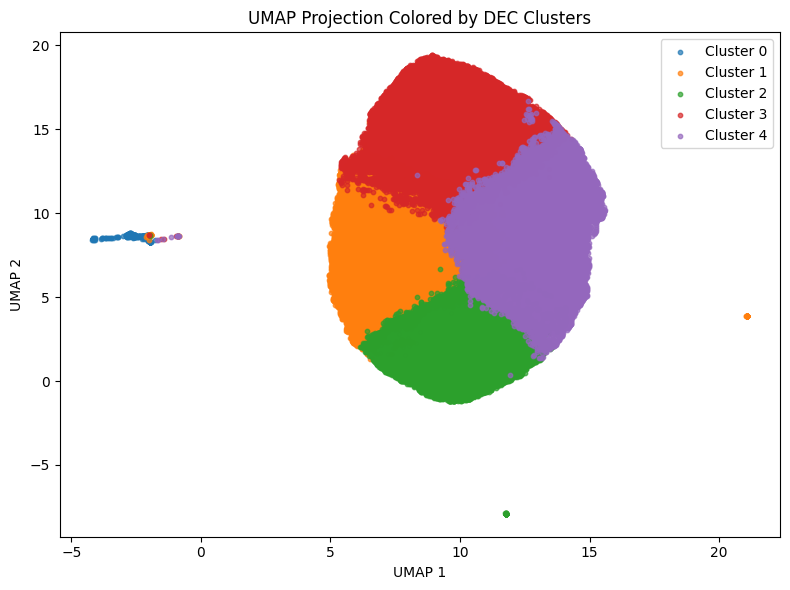

UMAP figure saved to: ..\final_dec\figures\umap_clusters.png


In [31]:
import matplotlib.pyplot as plt

# Create figures directory
figures_dir = "../final_dec/figures"
Path(figures_dir).mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 6))

# Plot each cluster separately
for cluster_id in np.unique(labels):
    mask = labels == cluster_id
    plt.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        s=10,
        alpha=0.7,
        label=f"Cluster {cluster_id}",
    )

plt.title("UMAP Projection Colored by DEC Clusters")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend()
plt.tight_layout()

output_path = Path(figures_dir) / "umap_clusters.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"UMAP figure saved to: {output_path}")

## Cluster profiles

Cluster profiling is performed using the original interpretable feature representation rather than the UMAP coordinates.

For each final DEC cluster, we calculate the mean and standard deviation of each original feature and compute feature-level z-scores relative to the overall dataset. These z-scores are then used to identify the features that are relatively higher or lower in each cluster.

In [32]:
import numpy as np
import pandas as pd
from pathlib import Path

# Paths
cluster_profile_dir = Path("../final_dec/cluster_profiles/")
cluster_profile_dir.mkdir(parents=True, exist_ok=True)


# Load final labels
labels = np.load("../final_dec/model/final_labels.npy")

# Load original interpretable feature data
df = pd.read_excel("../dataset/compressed_features.xlsx")

df = df.dropna().reset_index(drop=True)

print("Profile data shape:", df.shape)
print("Labels shape:", labels.shape)

# Verify row alignment
if len(df) != len(labels):
    raise ValueError(
        f"Row mismatch: dataset has {len(df)} rows but "
        f"labels have {len(labels)} entries."
    )

# Cluster sizes
cluster_counts = (
    pd.Series(labels, name="cluster")
    .value_counts()
    .sort_index()
)

print("\nCluster sizes:")
print(cluster_counts)

cluster_counts.to_csv(
    cluster_profile_dir  / "cluster_counts.csv",
    header=["size"]
)

# Select numerical features
df_num = df.select_dtypes(include=[np.number]).copy()

# Make sure the expected feature count is correct
print("\nNumber of numerical features:", df_num.shape[1])

df_num["cluster"] = labels

# Cluster means and standard deviations
cluster_means = df_num.groupby("cluster").mean()
cluster_stds = df_num.groupby("cluster").std()

# Feature-level z-scores relative to global population
features = df_num.drop(columns="cluster")

global_mean = features.mean()
global_std = features.std()

cluster_z = (
    (cluster_means - global_mean)
    / (global_std + 1e-12)
)

# Save complete profile tables
cluster_means.to_csv(
    cluster_profile_dir / "cluster_feature_mean.csv"
)

cluster_stds.to_csv(
    cluster_profile_dir / "cluster_feature_std.csv"
)

cluster_z.to_csv(
    cluster_profile_dir / "cluster_feature_zscore.csv"
)

# Extract top positive / negative characteristics
topk = 8
profiles = {}

for cluster_id in cluster_z.index:
    z_scores = cluster_z.loc[cluster_id]

    # Only genuinely above-average features
    top_pos = (
        z_scores[z_scores > 0]
        .sort_values(ascending=False)
        .head(topk)
    )

    # Only genuinely below-average features
    top_neg = (
        z_scores[z_scores < 0]
        .sort_values(ascending=True)
        .head(topk)
    )

    profiles[cluster_id] = {
        "top_pos": top_pos,
        "top_neg": top_neg,
    }


# Create readable profile text
def readable_profile(cluster_id, top_pos, top_neg, count):
    lines = []

    lines.append(f"Cluster {cluster_id} (N={count}):")

    lines.append("  Characteristics (higher than average):")

    if len(top_pos) == 0:
        lines.append("    - None")
    else:
        for feature, z in top_pos.items():
            lines.append(f"    - {feature}: z={z:.2f}")

    lines.append("  Characteristics (lower than average):")

    if len(top_neg) == 0:
        lines.append("    - None")
    else:
        for feature, z in top_neg.items():
            lines.append(f"    - {feature}: z={z:.2f}")

    return "\n".join(lines)


profiles_text = []

for cluster_id in sorted(profiles.keys()):
    top_pos = profiles[cluster_id]["top_pos"]
    top_neg = profiles[cluster_id]["top_neg"]

    text = readable_profile(
        cluster_id,
        top_pos,
        top_neg,
        int(cluster_counts.loc[cluster_id]),
    )

    profiles_text.append(text)


# Save corrected readable profiles
profiles_path = cluster_profile_dir / "cluster_profiles.txt"

with open(profiles_path, "w", encoding="utf-8") as f:
    f.write("\n\n".join(profiles_text))


# Display corrected profiles
print("\n" + "\n\n".join(profiles_text))

print("\nCluster profile artifacts saved:")
print(f"- {cluster_profile_dir / 'cluster_counts.csv'}")
print(f"- {cluster_profile_dir / 'cluster_feature_mean.csv'}")
print(f"- {cluster_profile_dir / 'cluster_feature_std.csv'}")
print(f"- {cluster_profile_dir / 'cluster_feature_zscore.csv'}")
print(f"- {profiles_path}")

Profile data shape: (99997, 7)
Labels shape: (99997,)

Cluster sizes:
cluster
0      489
1    28258
2    20515
3    25483
4    25252
Name: count, dtype: int64

Number of numerical features: 7

Cluster 0 (N=489):
  Characteristics (higher than average):
    - None
  Characteristics (lower than average):
    - Lifestyle: z=-6.27
    - Communication: z=-6.25
    - Responsibility: z=-5.86
    - Openness: z=-5.46
    - Interests: z=-5.13
    - EmotionalStability: z=-4.89
    - SocialEngagement: z=-4.25

Cluster 1 (N=28258):
  Characteristics (higher than average):
    - SocialEngagement: z=0.64
    - EmotionalStability: z=0.56
    - Interests: z=0.19
    - Communication: z=0.07
    - Lifestyle: z=0.03
  Characteristics (lower than average):
    - Openness: z=-0.52
    - Responsibility: z=-0.19

Cluster 2 (N=20515):
  Characteristics (higher than average):
    - SocialEngagement: z=0.66
    - Openness: z=0.55
    - EmotionalStability: z=0.51
    - Communication: z=0.49
    - Responsibility: 

In [35]:
import json
import numpy as np
from pathlib import Path

# Paths
final_dec_dir = Path("../final_dec")

# Load final metrics
with open(final_dec_dir / "metrics" / "metrics.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

# Load cluster sizes
with open(final_dec_dir / "cluster_profiles" / "cluster_sizes.json", "r", encoding="utf-8") as f:
    cluster_size_data = json.load(f)

# Load training history
with open(final_dec_dir / "metrics" / "training_history.json", "r", encoding="utf-8") as f:
    training_history = json.load(f)

# Load final labels to obtain the final sample count
labels = np.load(final_dec_dir / "model" / "final_labels.npy")

# Final configuration
n_samples = len(labels)
n_features = 7
n_clusters = len(cluster_size_data["cluster_sizes"])

seed = 42
alpha = ALPHA
learning_rate = LEARNING_RATE
update_interval = training_history["update_interval"]
batch_size = BATCH_SIZE
epochs = training_history["epochs"]

# Print compact final summary
print("FINAL DEC RESULTS SUMMARY")
print("=" * 40)

print(f"N samples:        {n_samples:,}")
print(f"N features:       {n_features}")
print(f"N clusters:       {n_clusters}")
print(f"Seed:             {seed}")
print(f"Alpha:            {alpha}")
print(f"Learning rate:    {learning_rate}")
print(f"Update interval:  {update_interval}")
print(f"Batch size:       {batch_size}")
print(f"Epochs:           {epochs}")

print("\nClustering quality:")
print(f"Silhouette:       {metrics['silhouette_score']:.4f}")
print(f"Davies-Bouldin:   {metrics['davies_bouldin_index']:.4f}")
print(f"Calinski-Harabasz:{metrics['calinski_harabasz_score']:.2f}")

print("\nAssignment uncertainty:")
print(f"Mean entropy:     {metrics['entropy_metrics']['mean_entropy']:.4f}")
print(f"Std entropy:      {metrics['entropy_metrics']['std_entropy']:.4f}")

print("\nOptimization:")
print(f"Final KL:         {metrics['optimization_metrics']['final_train_kl']:.6f}")

print("\nCluster sizes:")
for cluster_id, size in cluster_size_data["cluster_sizes"].items():
    print(f"Cluster {cluster_id}: {size:,}")

FINAL DEC RESULTS SUMMARY
N samples:        99,997
N features:       7
N clusters:       5
Seed:             42
Alpha:            0.5
Learning rate:    0.003
Update interval:  20
Batch size:       256
Epochs:           50

Clustering quality:
Silhouette:       0.2358
Davies-Bouldin:   1.0984
Calinski-Harabasz:33874.73

Assignment uncertainty:
Mean entropy:     1.4455
Std entropy:      0.0650

Optimization:
Final KL:         0.065057

Cluster sizes:
Cluster 0: 489
Cluster 1: 28,258
Cluster 2: 20,515
Cluster 3: 25,483
Cluster 4: 25,252


### Interpretation of the final DEC solution

The final Deep Embedded Clustering (DEC) solution was obtained for 99,997 samples represented by seven numerical features and partitioned into five clusters. The resulting clustering provides a structured segmentation of the dataset, although the internal evaluation metrics indicate that the clusters are not completely separated. The Silhouette score was 0.2358, while the Davies–Bouldin index was 1.0984 and the Calinski–Harabasz score was 33,874.73. Together, these values indicate meaningful structure in the learned representation, but also substantial proximity or overlap between some clusters. The final solution should therefore be interpreted as a structured partition of a continuous behavioral feature space rather than five sharply isolated groups.

The assignment uncertainty provides further support for this interpretation. The mean entropy of the soft cluster assignments was 1.4455, with a standard deviation of 0.0650. For five clusters, the maximum possible entropy under a uniform assignment is approximately 1.6094. The observed mean entropy is therefore relatively high, indicating that many observations retain non-negligible assignment probabilities across multiple clusters. This suggests that the boundaries between some of the discovered groups are not highly distinct and that the clustering contains a considerable degree of assignment uncertainty. Consequently, the cluster labels are better viewed as dominant memberships within a continuous structure rather than completely unambiguous class assignments.

The optimization history also shows that the KL-divergence objective did not decrease monotonically throughout training. The minimum training KL value was 0.0340 at epoch 4, after which the objective remained close to this level until approximately epoch 20. A marked increase occurred after this point, with the KL value rising to approximately 0.062 and subsequently to approximately 0.065 near the final training stage. The final KL value was 0.0651, while the mean and standard deviation across the recorded epochs were 0.0516 and 0.0143, respectively. These increases occur around the periodic target-distribution update points used during DEC training. This indicates that the optimization trajectory was affected by the iterative refinement of the target assignments and that the final state was not simply the minimum-KL state observed during training. The final clustering is therefore evaluated using the complete set of final-state clustering and uncertainty measures rather than the minimum KL value alone.

The cluster-size distribution shows a pronounced imbalance. Cluster 0 contains only 489 observations, whereas the remaining clusters contain between 20,515 and 28,258 observations. The largest cluster is therefore approximately 58 times larger than the smallest cluster. This indicates that Cluster 0 represents a very small subgroup of the dataset rather than a partition of approximately equal-sized populations. This imbalance is an important characteristic of the final solution and should be considered when interpreting Cluster 0. In particular, its profile should not be treated as equally representative of the overall dataset as the profiles of the larger clusters.

The two-dimensional UMAP projection provides a visual representation of the learned five-dimensional embeddings, but it is used only for visualization and interpretation and was not involved in DEC training or hyperparameter selection. The projection shows a large central region in which the five cluster assignments substantially overlap, rather than five clearly separated islands. The clusters nevertheless occupy partially different regions of the projection: Cluster 3 is concentrated toward the upper part of the main structure, Cluster 2 is more prominent toward the lower region, and Cluster 4 is concentrated toward the right side. Cluster 1 occupies a broad central-to-upper region, while the small Cluster 0 is largely concentrated in a small region to the left of the main structure, with a limited number of observations appearing within or around the larger groups. The projection therefore supports differences among the learned groups while also visually confirming that the cluster boundaries are not completely separated. The isolated observations visible in parts of the projection further suggest that some observations are positioned away from the dominant regions of their assigned clusters. Because UMAP is a nonlinear two-dimensional projection, however, these visual relationships should not be interpreted as direct evidence of separability in the original or learned space.

The feature-level profiles provide a more interpretable description of the five clusters using the original seven behavioral dimensions. Cluster 0 is clearly distinguished by substantially below-average values across all seven features. Its standardized differences are particularly large, ranging from approximately -4.25 for SocialEngagement to -6.27 for Lifestyle. This makes Cluster 0 an extreme low-value subgroup across the measured dimensions rather than a group characterized by one or two selectively elevated traits. Its very small size further supports the interpretation of this cluster as a distinct minority subgroup.

Cluster 1 is characterized primarily by above-average SocialEngagement (z = 0.64) and EmotionalStability (z = 0.56), with smaller positive deviations for Interests, Communication, and Lifestyle. Openness (z = -0.52) and Responsibility (z = -0.19) are comparatively lower. The dominant profile of this cluster is therefore associated with relatively stronger social engagement and emotional stability, while openness and responsibility are comparatively less prominent.

Cluster 2 also shows relatively high SocialEngagement (z = 0.66), together with elevated Openness (z = 0.55), EmotionalStability (z = 0.51), Communication (z = 0.49), and Responsibility (z = 0.34). In contrast, Interests (z = -0.76) and Lifestyle (z = -0.42) are below the global average. Compared with Cluster 1, this group combines similarly elevated social engagement and emotional stability with stronger openness, communication, and responsibility, while showing lower levels of interests and lifestyle scores.

Cluster 3 is primarily distinguished by higher Interests (z = 0.74) and Lifestyle (z = 0.46). All remaining features are below the global average, with the largest negative deviation occurring for SocialEngagement (z = -0.70), followed by EmotionalStability (z = -0.40), Openness (z = -0.37), Responsibility (z = -0.32), and Communication (z = -0.18). This profile represents a group whose most prominent characteristics are higher interests and lifestyle scores combined with comparatively lower social engagement and lower values across several of the remaining dimensions.

Cluster 4 is characterized most strongly by above-average Openness (z = 0.61) and Responsibility (z = 0.37). At the same time, EmotionalStability (z = -0.55) and SocialEngagement (z = -0.45) are below average. Interests (z = -0.24), Communication (z = -0.17), and Lifestyle (z = -0.03) are also slightly below the global average. This distinguishes Cluster 4 from Clusters 1 and 2, which have comparatively higher social engagement and emotional stability.

The final DEC solution identifies five groups with distinguishable feature profiles, but the evidence does not support interpreting them as five completely discrete populations. The moderate Silhouette score, the Davies–Bouldin value, the relatively high assignment entropy, and the substantial overlap visible in the UMAP projection all indicate that the discovered structure contains considerable continuity between groups. At the same time, the cluster profiles reveal consistent differences across the original behavioral dimensions, suggesting that the partition captures meaningful variation in the dataset. The main structural caveat is the pronounced size imbalance, particularly the very small Cluster 0, which should be considered when interpreting the stability and generalizability of that subgroup. These results provide an interpretable final clustering structure while reflecting the uncertainty and overlap present in the underlying data.
